# COCO Car Damage — повреждения и детали

Данные: `datasets/Coco Car Damage Detection Dataset/`. `ANNOTATION_MODE`: `damage` — повреждения, `parts` — детали, `both` — оба вида разметки на одном фото. Числовые ID разрешаются через `categories` своего файла.

`SPLIT`: `train`, `val`, `test`, `all`. У `test` нет аннотаций: для его просмотра оставьте `ONLY_ANNOTATED = False`.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "Coco Car Damage Detection Dataset"
SPLIT = "train"
ANNOTATION_MODE = "damage"    # "damage", "parts", "both"
N_IMAGES = 6
N_COLS = 3
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
def load_dataset(root, annotation_mode="damage"):
    if annotation_mode not in {"damage", "parts", "both"}:
        raise ValueError('ANNOTATION_MODE: "damage", "parts" или "both".')
    modes = ("damage", "parts") if annotation_mode == "both" else (annotation_mode,)
    indexed = {}
    for split_name in ("train", "val"):
        for mode in modes:
            prefix = "COCO_mul" if mode == "parts" else "COCO"
            path = root / split_name / f"{prefix}_{split_name}_annos.json"
            for sample in load_coco(path, root / split_name, split_name, fallback_dir=root / "img"):
                key = (split_name, sample["file_name"])
                if key not in indexed:
                    indexed[key] = sample
                else:
                    indexed[key]["annotations"].extend(sample["annotations"])
    for image in image_files(root / "test"):
        indexed[("test", image.name)] = {
            "image_path": image, "file_name": image.name, "split": "test",
            "annotations": [], "metadata": {"file_name": image.name}, "task": "segmentation",
        }
    return list(indexed.values())

dataset = load_dataset(DATASET_ROOT, ANNOTATION_MODE)
summary = summarize(dataset)


Записей: 78; изображения отсутствуют: 0
Выборки: {'train': 59, 'val': 11, 'test': 8}
Классы (число меток):
  damage: 164


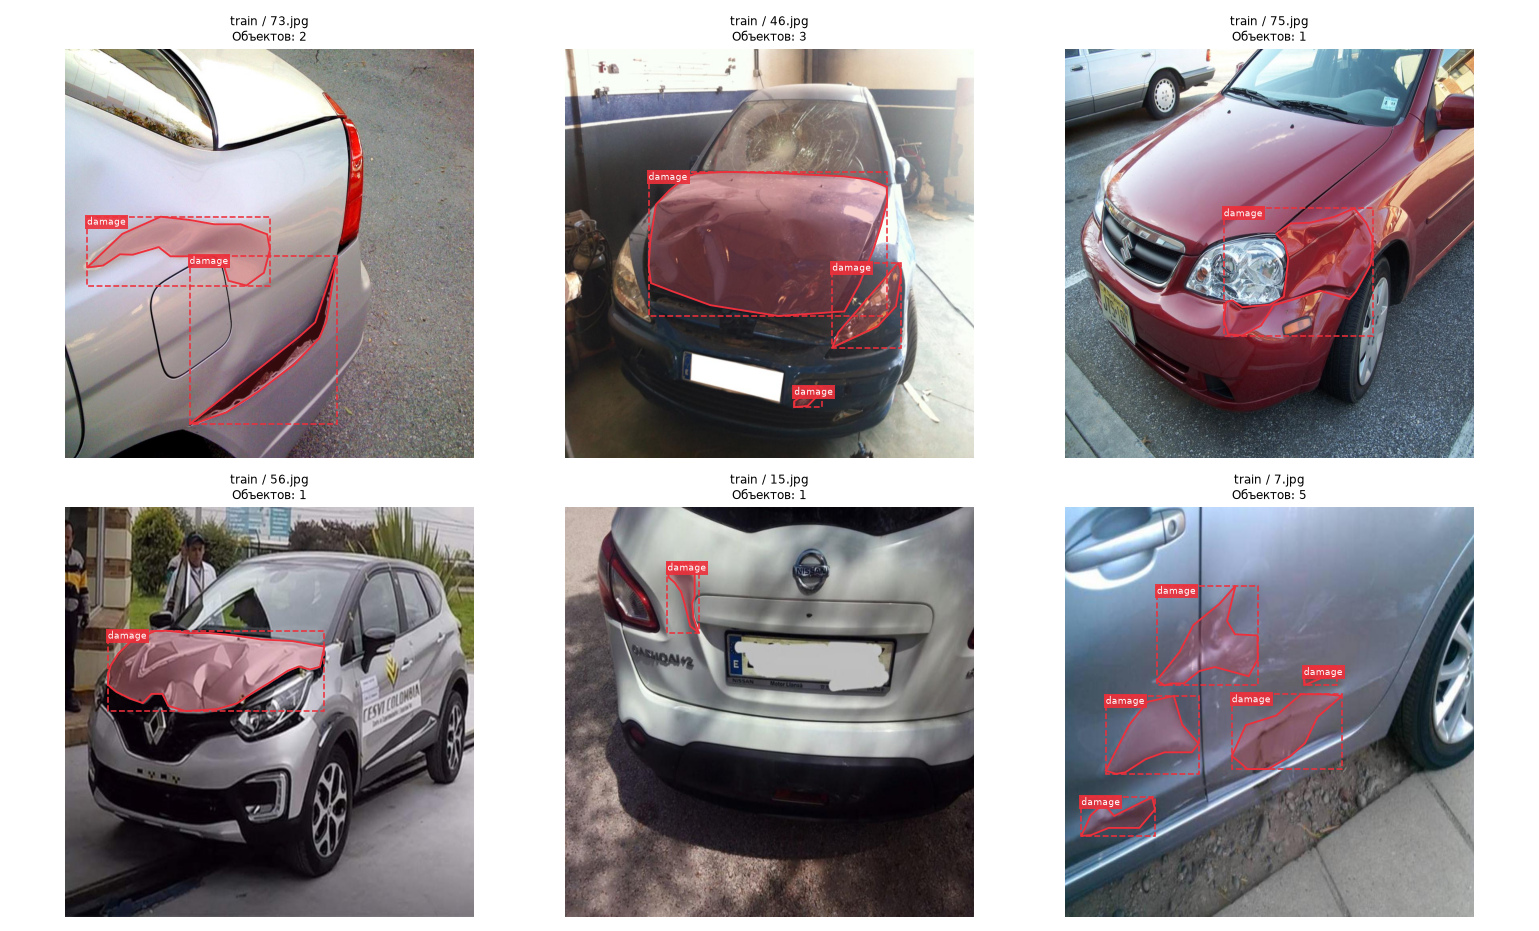

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED,
)
